In [1]:
import torch
import torch.nn as nn

In [2]:
x = torch.tensor([
    [-1, -1],
    [-1,  1],
    [ 1, -1],
    [ 1,  1],
], dtype=torch.float32)

y = torch.tensor([
    [0],
    [1],
    [1],
    [0],
], dtype=torch.float32)

In [8]:
layer = nn.Linear(2,1)
optimizer = torch.optim.SGD(layer.parameters(), lr = 0.1)
loss_api = nn.BCEWithLogitsLoss()
for step in range(500):
    optimizer.zero_grad(set_to_none=True)
    y_predict = layer(x)
    loss = loss_api(y_predict,y)
    loss.backward()
    optimizer.step()
    with torch.no_grad():
        y_predict = layer(x)
        loss = loss_api(y_predict,y)
        if (step + 1) % 100 == 0:
            print(f"Step {step + 1}: loss={loss.item():.6f}")
            print("Logits:", y_predict.tolist())
            print("sigmoid:",torch.sigmoid(y_predict))
            print("label:",(torch.sigmoid(y_predict) >= 0.5).long())


Step 100: loss=0.693534
Logits: [[-0.007491175085306168], [0.06906779110431671], [0.009752953425049782], [0.08631192147731781]]
sigmoid: tensor([[0.4981],
        [0.5173],
        [0.5024],
        [0.5216]])
label: tensor([[0],
        [1],
        [1],
        [1]])
Step 200: loss=0.693150
Logits: [[-0.0005959386471658945], [0.005493472330272198], [0.0007758068386465311], [0.006865218281745911]]
sigmoid: tensor([[0.4999],
        [0.5014],
        [0.5002],
        [0.5017]])
label: tensor([[0],
        [1],
        [1],
        [1]])
Step 300: loss=0.693147
Logits: [[-4.736523260362446e-05], [0.0004368303925730288], [6.170060078147799e-05], [0.0005458962405100465]]
sigmoid: tensor([[0.5000],
        [0.5001],
        [0.5000],
        [0.5001]])
label: tensor([[0],
        [1],
        [1],
        [1]])
Step 400: loss=0.693147
Logits: [[-3.767398084164597e-06], [3.4722550481092185e-05], [4.882489520241506e-06], [4.3372441723477095e-05]]
sigmoid: tensor([[0.5000],
        [0.5000],

In [9]:
layer1 = nn.Linear(2,4)
layer2 = nn.Linear(4,1)
y_1 = layer1(x)
y_2 = torch.relu(y_1)
y_3 = layer2(y_2)
print("第一层输出:", y_1.shape)
print("ReLU 后:", y_2.shape)
print("最终 logits:", y_3.shape)

print("第一条样本，ReLU 前:", y_1[0])
print("第一条样本，ReLU 后:", y_2[0])

第一层输出: torch.Size([4, 4])
ReLU 后: torch.Size([4, 4])
最终 logits: torch.Size([4, 1])
第一条样本，ReLU 前: tensor([-0.8499,  0.9195,  1.5211, -0.3758], grad_fn=<SelectBackward0>)
第一条样本，ReLU 后: tensor([0.0000, 0.9195, 1.5211, 0.0000], grad_fn=<SelectBackward0>)


In [3]:
layer1 = nn.Linear(2,4)
layer2 = nn.Linear(4,1)
optimizer = torch.optim.SGD(list(layer1.parameters()) + list(layer2.parameters()) , lr= 0.1)
loss_api = nn.BCEWithLogitsLoss()
for step in range(3000):
    optimizer.zero_grad(set_to_none=True)
    y_1 = layer1(x)
    y_2 = torch.relu(y_1)
    y_3 = layer2(y_2)
    loss =loss_api(y_3,y)
    loss.backward()
    optimizer.step()
    with torch.no_grad():
        y_1 = layer1(x)
        y_2 = torch.relu(y_1)
        y_3 = layer2(y_2)
        loss =loss_api(y_3,y)

        if (step + 1) % 500 == 0:
            print(f"Step {step + 1}: loss={loss.item():.6f}")
            print("Logits:", y_3.tolist())
            print("sigmoid:",torch.sigmoid(y_3))
            print("label:",(torch.sigmoid(y_3) >= 0.5).long())
    

Step 500: loss=0.351259
Logits: [[0.00860567856580019], [4.554366588592529], [0.00860567856580019], [-4.79252290725708]]
sigmoid: tensor([[0.5022],
        [0.9896],
        [0.5022],
        [0.0082]])
label: tensor([[1],
        [1],
        [1],
        [0]])
Step 1000: loss=0.348302
Logits: [[0.0012366510927677155], [5.594180107116699], [0.0012366510927677155], [-5.742188930511475]]
sigmoid: tensor([[0.5003],
        [0.9963],
        [0.5003],
        [0.0032]])
label: tensor([[1],
        [1],
        [1],
        [0]])
Step 1500: loss=0.347550
Logits: [[0.00034738396061584353], [6.213160991668701], [0.00034738396061584353], [-6.263363361358643]]
sigmoid: tensor([[0.5001],
        [0.9980],
        [0.5001],
        [0.0019]])
label: tensor([[1],
        [1],
        [1],
        [0]])
Step 2000: loss=0.347262
Logits: [[0.0002546312753111124], [6.552423477172852], [0.0002546312753111124], [-6.622440814971924]]
sigmoid: tensor([[0.5001],
        [0.9986],
        [0.5001],
       

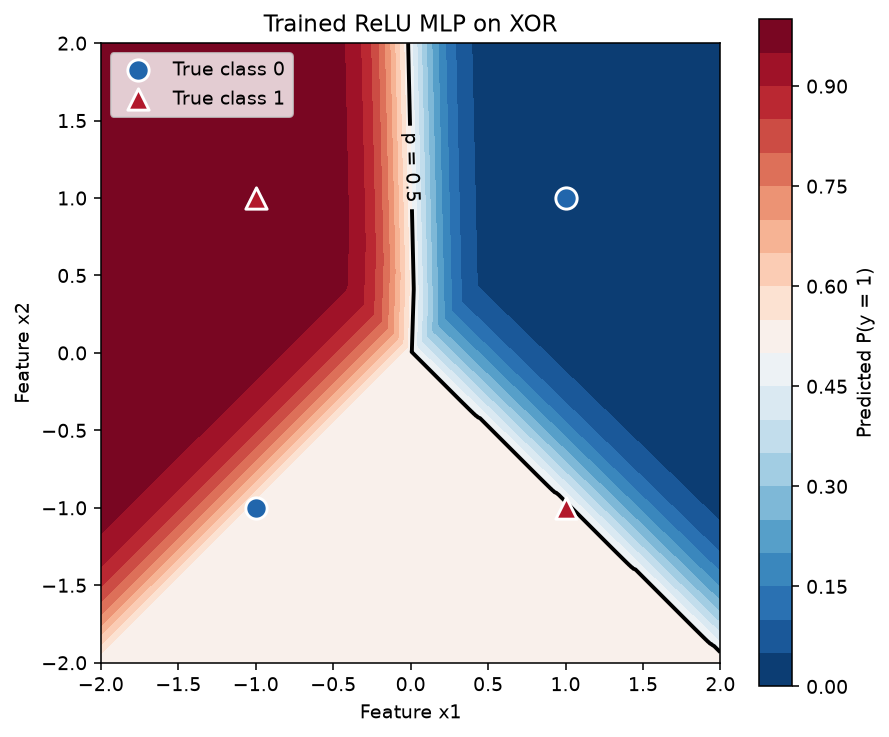

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# 在二维平面上生成网格，每个坐标都是一条待预测样本。
axis = np.linspace(-2, 2, 300)
xx, yy = np.meshgrid(axis, axis)

grid = torch.tensor(
    np.column_stack([xx.ravel(), yy.ravel()]),
    dtype=layer1.weight.dtype,
    device=layer1.weight.device,
)

# 使用你实际训练好的两层参数，不重新训练。
with torch.no_grad():
    hidden = torch.relu(layer1(grid))
    logits = layer2(hidden)
    probabilities = torch.sigmoid(logits)
    probability_map = probabilities.cpu().numpy().reshape(xx.shape)

points = x.detach().cpu().numpy()
labels = y.detach().cpu().numpy().reshape(-1)

fig, ax = plt.subplots(figsize=(6.5, 5.5), dpi=140)

background = ax.contourf(
    xx, yy, probability_map,
    levels=np.linspace(0, 1, 21),
    cmap="RdBu_r",
    vmin=0,
    vmax=1,
)

if probability_map.min() < 0.5 < probability_map.max():
    boundary = ax.contour(
        xx, yy, probability_map,
        levels=[0.5],
        colors="black",
        linewidths=2,
    )
    ax.clabel(boundary, fmt={0.5: "p = 0.5"}, fontsize=10)

for label, color, marker in [
    (0, "#2166AC", "o"),
    (1, "#B2182B", "^"),
]:
    selected = labels == label
    ax.scatter(
        points[selected, 0],
        points[selected, 1],
        color=color,
        marker=marker,
        s=120,
        edgecolors="white",
        linewidths=1.5,
        label=f"True class {label}",
        zorder=3,
    )

fig.colorbar(background, ax=ax, label="Predicted P(y = 1)")
ax.set(
    title="Trained ReLU MLP on XOR",
    xlabel="Feature x1",
    ylabel="Feature x2",
    xlim=(-2, 2),
    ylim=(-2, 2),
)
ax.set_aspect("equal")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

In [5]:
with torch.no_grad():
    logits = layer2(torch.relu(layer1(x)))
    probabilities = torch.sigmoid(logits)
    predictions = (probabilities >= 0.5).long()

print("Probabilities:", probabilities.flatten().tolist())
print("Predictions:", predictions.flatten().tolist())
print("Labels:", y.flatten().tolist())

Probabilities: [0.5000233054161072, 0.9991633892059326, 0.5000233054161072, 0.000805905438028276]
Predictions: [1, 1, 1, 0]
Labels: [0.0, 1.0, 1.0, 0.0]


In [6]:
with torch.no_grad():
    before_relu = layer1(x)
    after_relu = torch.relu(before_relu)

print("ReLU 前：")
print(before_relu)
print("ReLU 后：")
print(after_relu)

ReLU 前：
tensor([[-1.4952e+00, -4.4207e-03, -2.7782e+00, -1.6820e+00],
        [ 8.8381e-03,  3.2435e+00,  1.3023e-02, -2.5819e-01],
        [-3.1187e-02, -3.2479e+00, -6.1411e-02, -3.5519e-01],
        [ 1.4728e+00, -4.2838e-05,  2.7298e+00,  1.0686e+00]])
ReLU 后：
tensor([[0.0000, 0.0000, 0.0000, 0.0000],
        [0.0088, 3.2435, 0.0130, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000],
        [1.4728, 0.0000, 2.7298, 1.0686]])
